# <center>🏠 Практика 4. Прогноз цены жилья и кластеризация K-means</center>
### <center>Прикладные технологии ИИ · 120 минут (2 ч.) · Модуль 2</center>

<div style='text-align: center; margin: 20px;'>
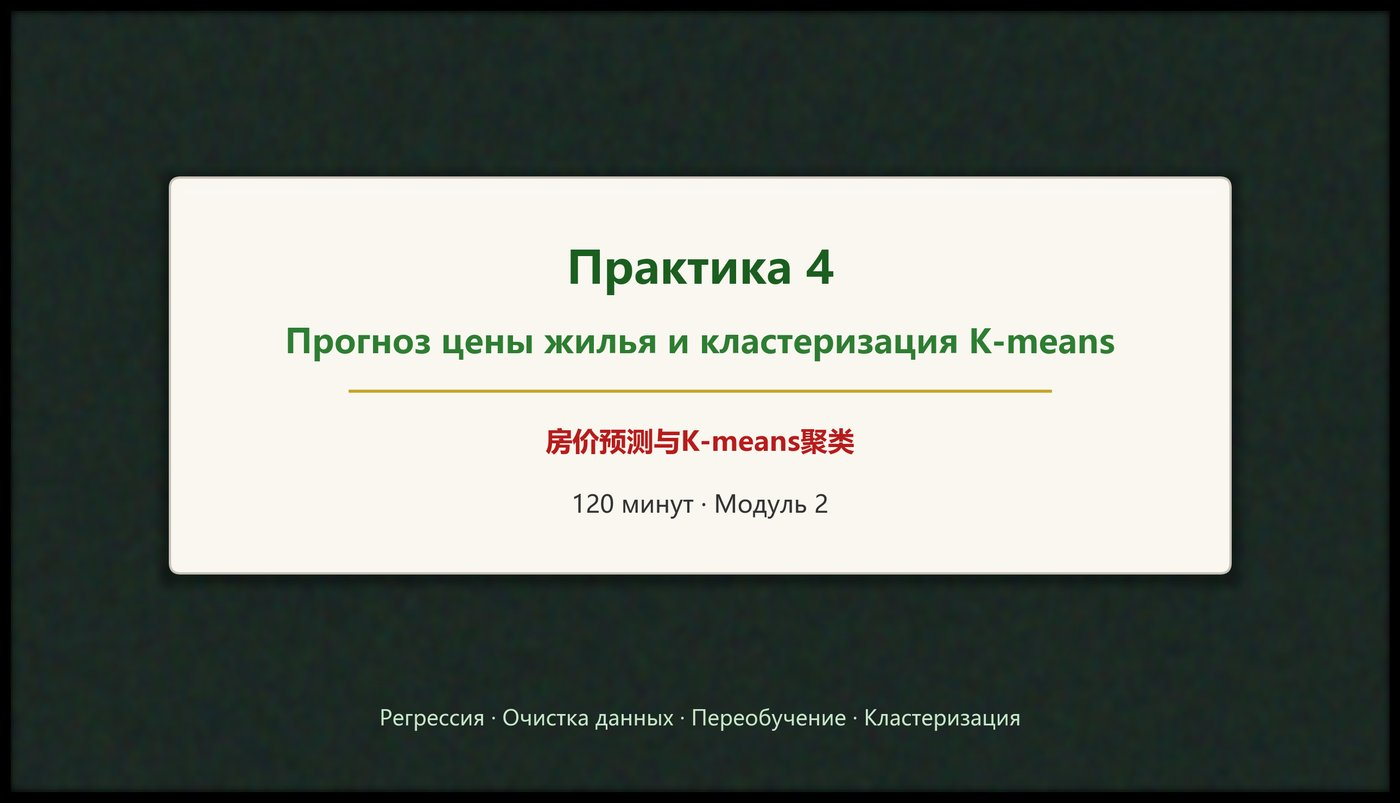
</div>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цель:</b> решить задачу регрессии и задачу кластеризации, очистить данные, сравнить модели и заметить переобучение.<br><br>
<b>⏱️ Ход работы (120 мин):</b> 10 мин — объяснение · 40 мин — регрессия · 15 мин — очистка данных · 35 мин — K-means · 20 мин — выводы и защита.
</div>

<div style='text-align: center; margin: 20px;'>
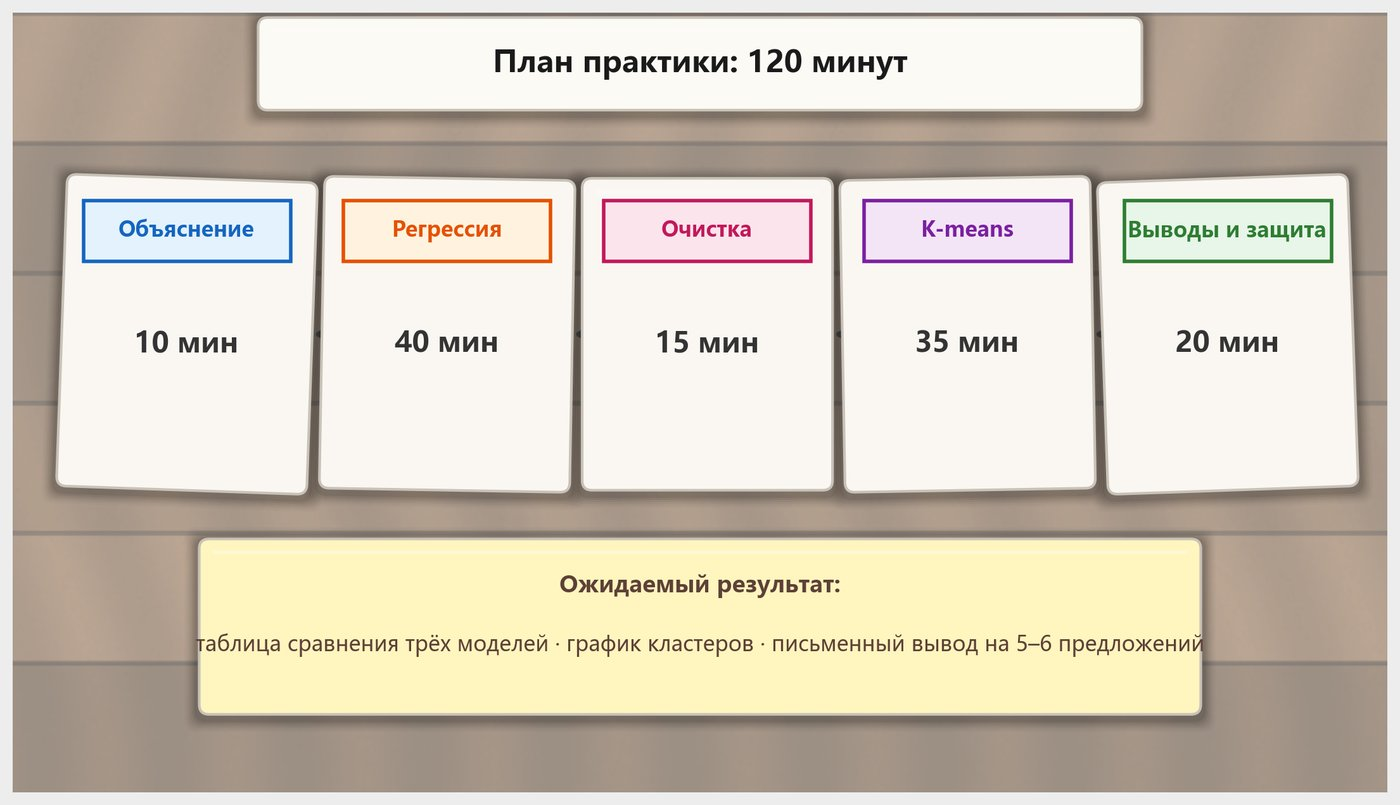
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #E65100;'>
<b>💡 Важно:</b> данные для регрессии создаются самим кодом (условный рынок жилья), поэтому скачивать ничего не нужно. Готовые зарубежные наборы часто лежат на недоступных серверах.
</div>

<center><i>Студент: _______________ · Группа: _______________ · Дата: _______________</i></center>

## 📘 Введение

**Регрессия** — это задача обучения с учителем, в которой целевая переменная
является **числом** (цена квартиры, температура воздуха, срок службы детали,
концентрация вещества). Модель учится по размеченным примерам `(xᵢ, yᵢ)`
предсказывать вещественное значение `ŷ = f(x)` для новых объектов. Это
принципиально отличает регрессию от **классификации**, где ответ — конечный
набор классов («болен/здоров», «кошка/собака», «спам/не спам»). Геометрически
классификация делит пространство признаков на области, а регрессия проводит
через него **поверхность** (гиперплоскость, кривую), которая аппроксимирует
зависимость «признаки → число».

**Кластеризация** — задача уже **без учителя**: правильных ответов `y` нет
вообще, а цель — обнаружить в данных внутреннюю структуру, группы похожих
объектов. Это полезно для сегментации клиентов, разбиения товаров,
поиска аномалий и как первый шаг перед обучением классификатора на
неразмеченных данных. Самый известный алгоритм — **K-means** — будет рассмотрен
во второй части практики.

Практика поделена на **две части**:

- **Часть А. Регрессия (≈ 40 мин)** — генерируем синтетический рынок жилья,
  портим данные пропусками и выбросами, чиним их медианой и фильтрацией,
  обучаем три модели (LinearRegression, DecisionTree глубины 3 и 10),
  сравниваем по MAE и R² и наблюдаем переобучение у глубокого дерева.
- **Часть Б. Кластеризация K-means (≈ 35 мин)** — берём классические данные
  ирисов, выбираем число кластеров методом локтя, визуализируем итог.

Между этими двумя половинами есть важная связка: и регрессия, и кластеризация
работают с одними и теми же признаками, но решают разные задачи — первая
предсказывает число по учителю, вторая ищет структуру без учителя.


In [1]:
# Ограничиваем число потоков, чтобы погасить предупреждение
# sklearn/KMeans о памяти при работе с MKL/OpenBLAS.
# ВАЖНО: переменные окружения нужно выставить ДО импорта numpy.
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# Настройка среды
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print('✅ Библиотеки готовы')

✅ Библиотеки готовы


### 🔍 Почему именно линейная регрессия и почему она может оказаться лучшей

**Линейная регрессия** — простейшая, но часто удивительно сильная модель.
Она предполагает, что целевое число `y` является **линейной комбинацией**
признаков:

```
y = w₁·x₁ + w₂·x₂ + ... + wₙ·xₙ + b
```

Здесь `x₁ ... xₙ` — признаки объекта (площадь, число комнат, возраст дома,
расстояние до метро), `w₁ ... wₙ` — **веса** (коэффициенты модели), а `b` —
**смещение** (bias, свободный член). Веса и смещение подбираются методом
**наименьших квадратов** (OLS): минимизируется сумма квадратов отклонений
прогноза от факта по обучающей выборке. У задачи есть закрытое решение —
так называемое *нормальное уравнение*, которое sklearn и решает численно.

**Почему именно линейная регрессия может оказаться лучшей в этой практике?**
Потому что синтетические данные о жилье сгенерированы по линейной формуле:

```
price = 2.0·area + 8·rooms − 0.6·age − 3·metro + 20 + шум
```

Когда **истинная зависимость в природе данных линейна**, модель той же формы
совпадает с «правилом генерации» — у неё нет причин ошибаться, кроме
неустранимого шума. Глубокое решающее дерево, напротив, способно подстроиться
под шум обучающей выборки (зазубрить его) и показать низкое качество на тесте
— это и есть **переобучение**, которое мы увидим дальше.

Линейную модель стоит пробовать **первой** в любой задаче регрессии: она
быстрая, интерпретируемая (вес признака = его вклад в цену), не склонна к
переобучению при разумном числе признаков и служит сильным baseline.


---
# 📈 Часть А. Регрессия (40 мин)

**Регрессия (回归)** — задача предсказания **числа** (цены, температуры, срока), а не класса.

<div style='text-align: center; margin: 20px;'>
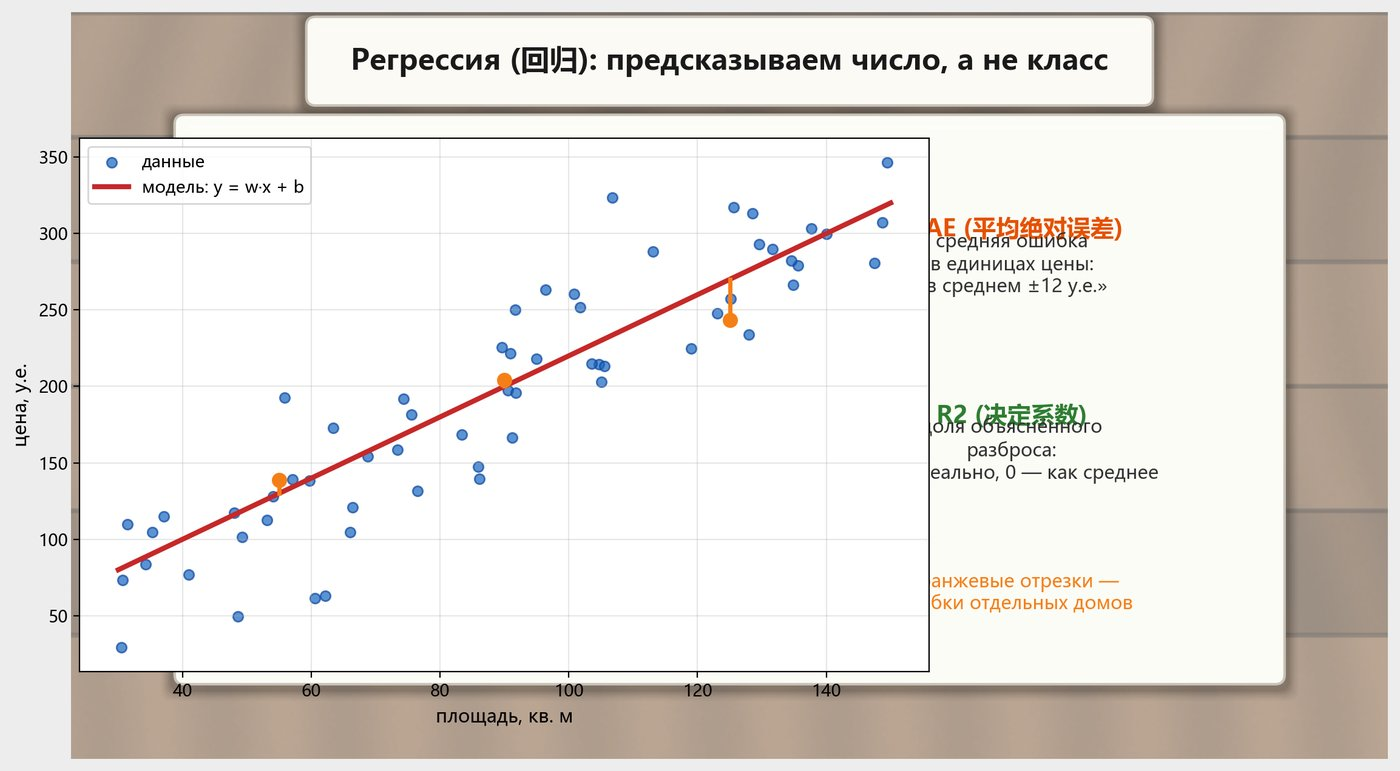
</div>

### Две метрики качества регрессии

| Метрика | 中文 | Формула (словами) | Как читать |
|---------|------|-------------------|------------|
| **MAE** | 平均绝对误差 | среднее абсолютных отклонений прогноза от факта | «в среднем ошибаемся на 12 у.е.» — в тех же единицах, что и цена |
| **R²** | 决定系数 | доля разброса цели, объяснённая моделью | 1 — идеально; 0 — не лучше предсказания средним; отрицательный — хуже среднего |

**Чем MAE отличается от R²?** MAE отвечает на вопрос «на сколько в среднем ошибаемся?» в понятных единицах (юани, метры). R² отвечает на вопрос «насколько модель лучше простого среднего?» и не зависит от масштаба данных.

## Шаг 1. Создаём учебные данные (условный рынок жилья)

Цена построена по **линейной формуле** с шумом — запомните это, позже мы обсудим, почему линейная модель окажется лучшей:

In [2]:
# 1. Учебные данные (цена в условных единицах)
rng = np.random.default_rng(42)
n = 300
area = rng.uniform(30, 150, n)       # площадь, кв. м
rooms = rng.integers(1, 5, n)        # комнат
age = rng.uniform(0, 40, n)          # возраст дома, лет
metro = rng.uniform(0.2, 10, n)      # расстояние до метро, км
price = 2.0*area + 8*rooms - 0.6*age - 3*metro + 20 + rng.normal(0, 10, n)
df = pd.DataFrame({'area': area, 'rooms': rooms, 'age': age, 'metro': metro, 'price': price})
df.to_csv('house.csv', index=False)

print('Таблица house.csv сохранена. Форма:', df.shape)
df.head()

Таблица house.csv сохранена. Форма: (300, 5)


,area,rooms,age,metro,price
0,122.874726,3,1.694022,2.751416,270.268340
1,82.665413,4,35.365828,3.360406,186.551843
2,133.031750,3,28.383131,2.576332,282.566121
3,113.684163,1,6.925114,4.902661,233.136955
4,41.301282,4,3.668840,6.895932,117.910483


**Разбор формулы цены:** `price = 2.0·area + 8·rooms − 0.6·age − 3·metro + 20 + шум`.
- Каждый квадратный метр добавляет 2 у.е.;
- каждая комната — 8 у.е.;
- каждый год возраста дома отнимает 0.6 у.е.;
- каждый километр до метро отнимает 3 у.е.

Шум `N(0, 10)` имитирует то, что в реальной жизни цена зависит ещё и от настроения продавца.

## Шаг 2. Очистка данных (15 мин)

<div style='text-align: center; margin: 20px;'>
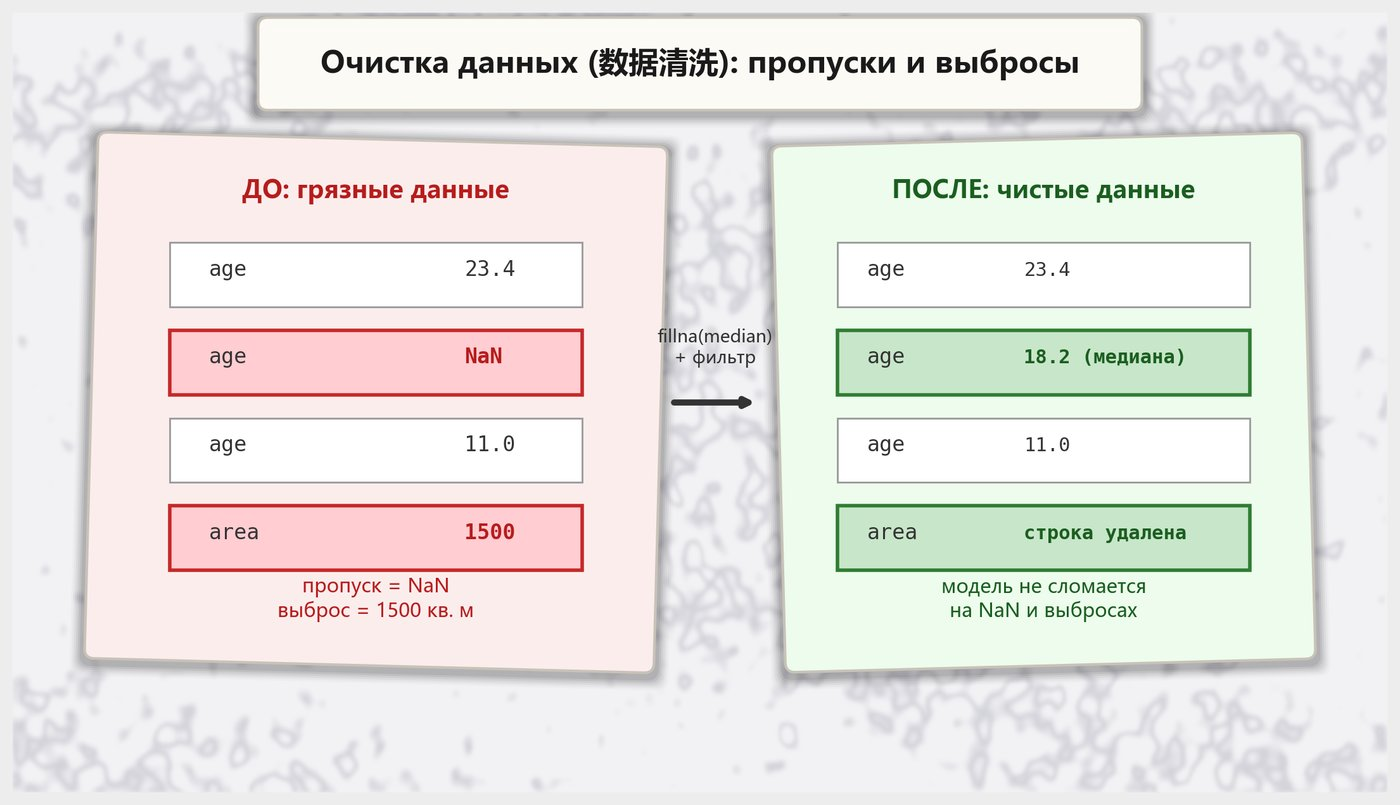
</div>

Испортим данные так, как это бывает в жизни: пропуски в `age` (анкета не заполнена) и выброс в `area` (опечатка: 1500 вместо 150). Затем починим:

In [3]:
# 2. Очистка: портим данные и чиним
dirty = df.copy()
dirty.loc[dirty.index[::25], 'age'] = np.nan   # пропуски
dirty.loc[5, 'area'] = 1500                    # выброс (ошибка ввода)
print('Пропусков:', dirty['age'].isna().sum())
print('Строк до очистки:', len(dirty))

dirty['age'] = dirty['age'].fillna(dirty['age'].median())  # пропуски -> медиана
dirty = dirty[dirty['area'] < 300]                          # выброс -> удалить

print('Пропусков после:', dirty['age'].isna().sum())
print('Строк после очистки:', len(dirty))

Пропусков: 12
Строк до очистки: 300
Пропусков после: 0
Строк после очистки: 299


**Почему медиана, а не среднее?** Медиана (中位数) устойчива к выбросам: одно огромное значение не сдвинет её. Среднее при выбросах врёт.

**Почему выброс удаляем, а не ограничиваем?** Площадь 1500 кв. м при максимуме генерации 150 — явная ошибка ввода, а не редкое, но реальное значение.

## Шаг 3. Обучение и сравнение трёх моделей

Обучим три модели и сравним их по MAE и R² **на тесте**, а также по R² **на обучении** — разрыв между ними и есть признак переобучения:

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 3. Обучение и сравнение моделей
X = dirty[['area', 'rooms', 'age', 'metro']]
y = dirty['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

results = []
for name, model in [('Линейная регрессия', LinearRegression()),
                    ('Дерево, глубина 3', DecisionTreeRegressor(max_depth=3, random_state=42)),
                    ('Дерево, глубина 10', DecisionTreeRegressor(max_depth=10, random_state=42))]:
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    mae = round(mean_absolute_error(y_test, p), 1)
    r2t = round(r2_score(y_test, p), 3)
    r2tr = round(model.score(X_train, y_train), 3)
    print(name, '| MAE =', mae, '| R2 тест =', r2t, '| R2 обучение =', r2tr)
    results.append({'Модель': name, 'MAE (тест)': mae, 'R2 тест': r2t, 'R2 обучение': r2tr})

table = pd.DataFrame(results)
print('\n=== ТАБЛИЦА СРАВНЕНИЯ (обязательный результат практики) ===')
display(table)

Линейная регрессия | MAE = 8.1 | R2 тест = 0.977 | R2 обучение = 0.982
Дерево, глубина 3 | MAE = 15.5 | R2 тест = 0.914 | R2 обучение = 0.956
Дерево, глубина 10 | MAE = 13.5 | R2 тест = 0.935 | R2 обучение = 1.0

=== ТАБЛИЦА СРАВНЕНИЯ (обязательный результат практики) ===


,Модель,MAE (тест),R2 тест,R2 обучение
0,Линейная регрессия,8.1,0.977,0.982
1,"Дерево, глубина 3",15.5,0.914,0.956
2,"Дерево, глубина 10",13.5,0.935,1.000


### 🎚️ Bias / Variance и как помогает регуляризация

Прежде чем обсуждать переобучение, полезно разобрать фундаментальный
**bias-variance tradeoff** — компромисс между смещением и разбросом.

- **Bias (смещение)** — насколько предсказания модели в среднем отклоняются
  от истинной зависимости. Высокий bias = **недообучение**: модель слишком
  проста (например, прямая для синусоиды) и систематически ошибается даже
  на обучающей выборке.
- **Variance (разброс)** — насколько предсказания меняются при замене
  обучающей выборки на другую из того же распределения. Высокая variance =
  **переобучение**: модель слишком сложна (глубокое дерево, полином высокой
  степени) и «зазубривает» шум обучающих данных, теряя обобщающую способность.

Чем сложнее модель, тем меньше bias и больше variance — и наоборот. Идеальная
модель балансирует между ними, минимизируя суммарную ошибку на новых данных.

**Регуляризация** — это способ искусственно добавить модели **bias**, чтобы
снизить её **variance** и тем самым бороться с переобучением. Идея: к
функции потерь добавляется штраф за большие веса:

- **L2-регуляризация (Ridge / гребневая регрессия):**
  `Loss = Σ(yᵢ − ŷᵢ)² + λ·Σwⱼ²` — веса плавно уменьшаются к нулю, но не
  обнуляются; хорошо работает, когда все признаки по чуть-чуть важны.
- **L1-регуляризация (Lasso / лассо):**
  `Loss = Σ(yᵢ − ŷᵢ)² + λ·Σ|wⱼ|` — часть весов становится строго нулевой;
  это даёт **разреженное** решение и работает как автоматический отбор
  признаков.
- **ElasticNet** комбинирует L1 + L2: `λ₁·Σ|wⱼ| + λ₂·Σwⱼ²`.

Параметр `λ` (в sklearn — `alpha`) управляет силой штрафа: при `λ = 0`
получаем обычную OLS, при больших `λ` — сильное упрощение модели. Подбирать
`λ` принято кросс-валидацией.

В этой практике у линейной регрессии нет заметного переобучения — у неё
всего 5 параметров на 300 объектов. А вот у дерева глубины 10 переобучение
налицо: R² на обучении почти 1, а на тесте ниже. Регуляризация дерева —
это `max_depth`, `min_samples_leaf` и `ccp_alpha` (post-pruning); для
линейной модели — переход от `LinearRegression` к `Ridge` или `Lasso`.


## Что обсудить после запуска

<div style='text-align: center; margin: 20px;'>
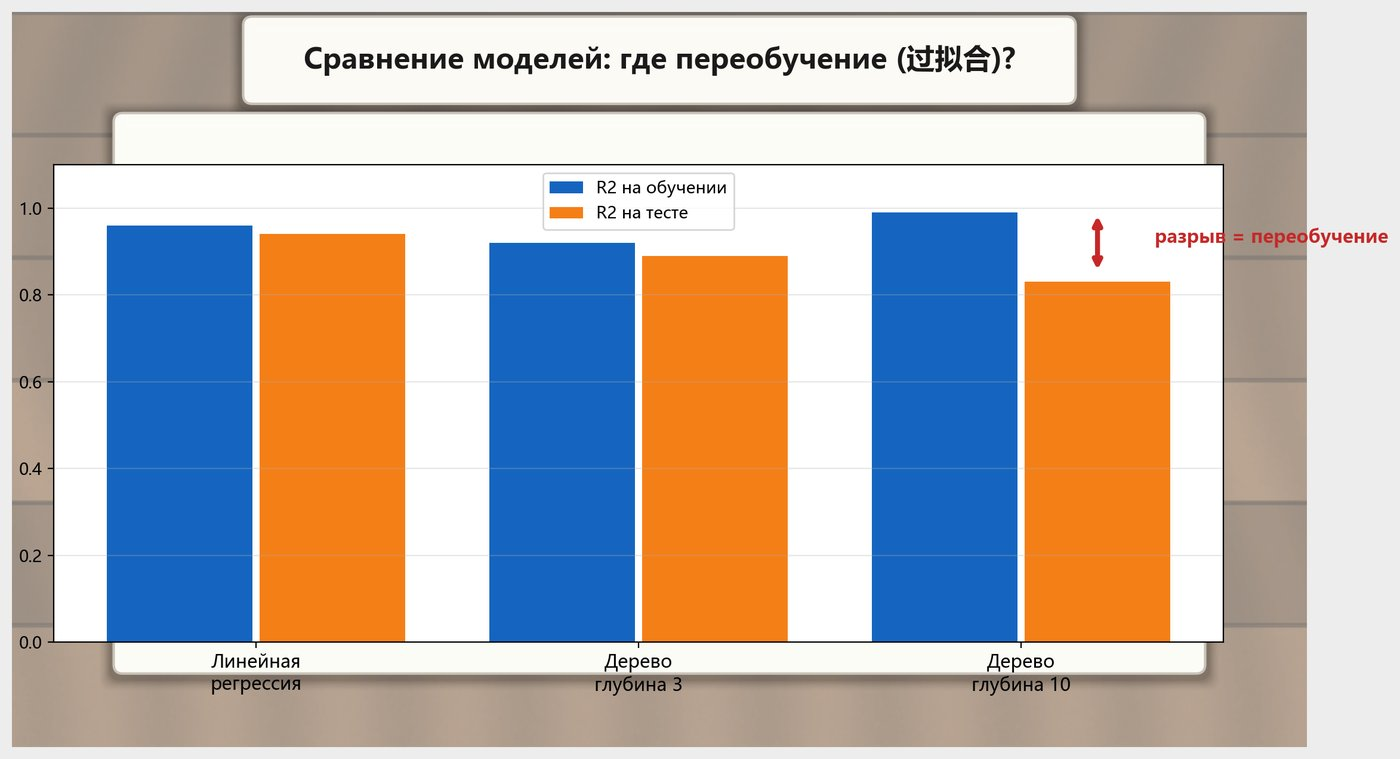
</div>

1. **Почему линейная регрессия, как правило, лучше всех?** Потому что данные созданы линейной формулой. Модель той же формы, что и природа данных, — идеальное совпадение.
2. **Где переобучение?** У глубокого дерева (глубина 10) R² на обучении почти равен 1, а на тесте заметно ниже: дерево «зазубрило» шум обучающей выборки. Разрыв между синим и оранжевым столбцом — и есть переобучение (过拟合).
3. **Чем MAE отличается от R²?** MAE — средняя ошибка в единицах цены (понятно человеку). R² — доля объяснённого разброса (удобно сравнивать модели на разных данных).

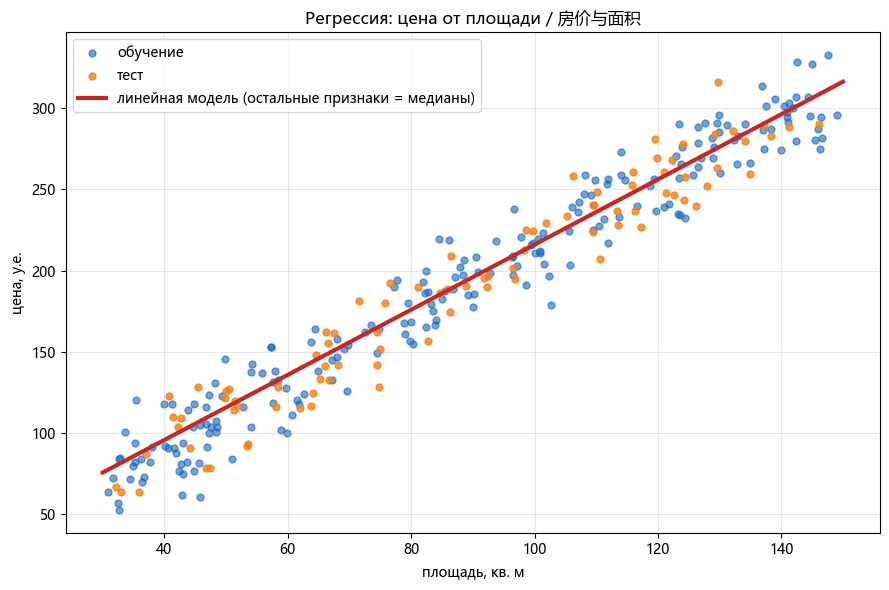

In [5]:
# Визуализация: площадь против цены + линия линейной модели
lin = LinearRegression().fit(X_train, y_train)
grid = np.linspace(30, 150, 60)
Xg = pd.DataFrame({
    'area': grid,
    'rooms': X_train['rooms'].median(),
    'age': X_train['age'].median(),
    'metro': X_train['metro'].median()
})

plt.figure(figsize=(9, 6))
plt.scatter(X_train['area'], y_train, s=25, c='#1565C0', alpha=0.6, label='обучение')
plt.scatter(X_test['area'], y_test, s=25, c='#F57F17', alpha=0.8, label='тест')
plt.plot(grid, lin.predict(Xg), color='#C62828', lw=3,
         label='линейная модель (остальные признаки = медианы)')
plt.xlabel('площадь, кв. м')
plt.ylabel('цена, у.е.')
plt.title('Регрессия: цена от площади / 房价与面积')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### ⚙️ Как работает алгоритм K-means

**K-means** — итеративный алгоритм разбиения `N` точек на `K` групп.
Он состоит из трёх шагов, которые повторяются до сходимости.

**1. Инициализация центроидов.** Выбираются `K` начальных центров кластеров
`μ₁, ..., μₖ`. В sklearn по умолчанию используется схема **k-means++**:
первый центроид берётся случайно, а каждый следующий выбирается из точек
данных с вероятностью, пропорциональной квадрату расстояния до уже выбранного
центроида. Это «разносит» центры в разные части данных и заметно улучшает
качество по сравнению с полностью случайным выбором.

**2. E-step (Expectation — шаг ожидания).** Каждая точка `xᵢ` относится к
тому кластеру, чей центроид к ней **ближайший**:

```
cluster(xᵢ) = argmin_k  ‖xᵢ − μₖ‖²
```

Это и есть «ожидание» меток при фиксированных центрах.

**3. M-step (Maximization — шаг максимизации).** Каждый центроид
**пересчитывается как среднее** всех точек, отнесённых к нему на E-step:

```
μₖ = (1 / |Cₖ|) · Σ_{xᵢ ∈ Cₖ} xᵢ
```

Это минимизирует суммарный разброс внутри групп (inertia) при фиксированных
метках.

**Критерий остановки.** Итерации E↔M повторяются, пока не выполнится одно из:
- центроиды **почти не сдвинулись** (изменение < `tol`, по умолчанию 1e-4);
- достигнут `max_iter` (по умолчанию 300);
- метки **перестали меняться**.

**Inertia** — это сумма квадратов расстояний от каждой точки до центра своего
кластера: `Σ ‖xᵢ − μ_{cluster(i)}‖²`. Чем больше `K`, тем меньше inertia
(в пределе `K = N` она равна 0). Поэтому по графику `inertia(K)` ищут
**«локоть»** — точку, после которой выигрыш от увеличения `K` становится
малым. Для ирисов это `K = 3`, что совпадает с тремя настоящими видами.


---
# 🧩 Часть Б. Кластеризация K-means (35 мин)

**Кластеризация (聚类)** — поиск групп похожих объектов **без учителя**: правильных ответов нет вообще.

**K-means** работает так: ставим K центров → каждый объект идёт к ближайшему центру → центры пересчитываются как среднее своей группы → повторяем, пока центры не замрут.

**inertia** — суммарный разброс точек внутри групп. Чем больше K, тем меньше inertia. Но после «правильного» K выигрыш становится крошечным — это и есть **«локоть»** на графике.

<div style='text-align: center; margin: 20px;'>
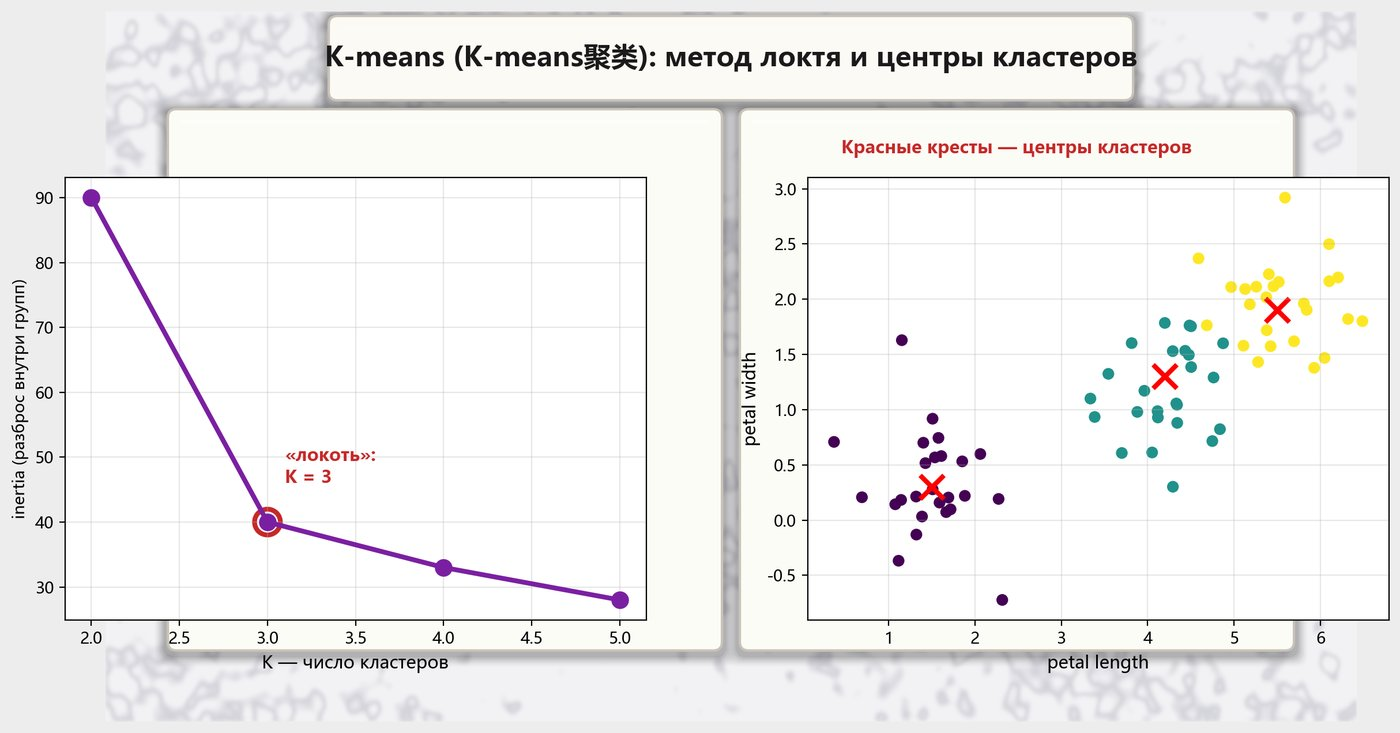
</div>

In [6]:
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris

data = load_iris(as_frame=True).data[['petal length (cm)', 'petal width (cm)']]

Ks, inertias = [], []
for k in [2, 3, 4, 5]:
    km = KMeans(n_clusters=k, n_init='auto', random_state=42).fit(data)
    Ks.append(k); inertias.append(km.inertia_)
    print('K =', k, '| разброс внутри групп =', round(km.inertia_, 1))

K = 2 | разброс внутри групп = 86.4
K = 3 | разброс внутри групп = 31.4
K = 4 | разброс внутри групп = 19.5
K = 5 | разброс внутри групп = 13.9


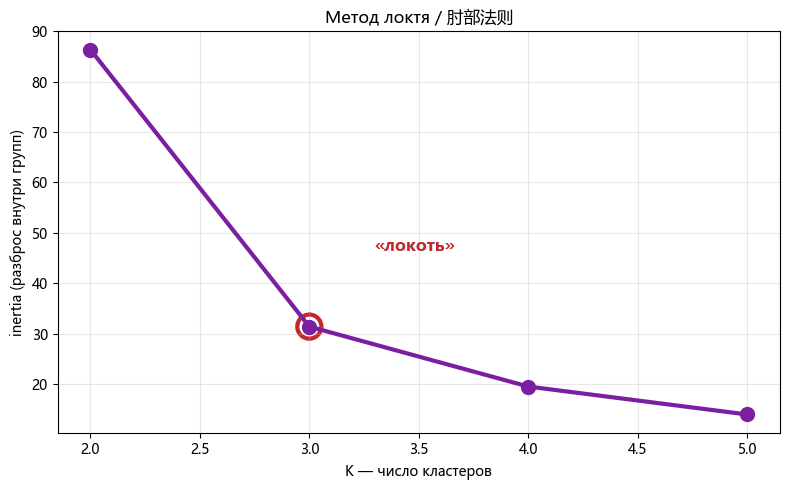

In [7]:
# Метод локтя: ищем K, после которого разброс почти не уменьшается
plt.figure(figsize=(8, 5))
plt.plot(Ks, inertias, 'o-', color='#7B1FA2', lw=3, ms=10)
plt.scatter([3], [inertias[1]], s=300, facecolors='none', edgecolors='#C62828', lw=3)
plt.annotate('«локоть»', xy=(3, inertias[1]), xytext=(3.3, inertias[1] + 15),
             fontsize=12, color='#C62828', fontweight='bold')
plt.xlabel('K — число кластеров')
plt.ylabel('inertia (разброс внутри групп)')
plt.title('Метод локтя / 肘部法则')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

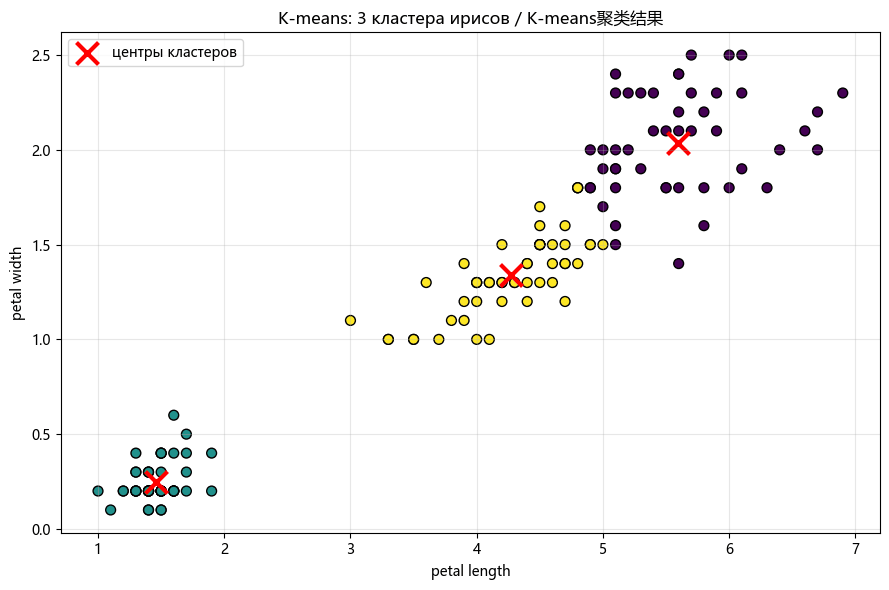

In [9]:
# Итоговая кластеризация при K = 3
km = KMeans(n_clusters=3, n_init='auto', random_state=42).fit(data)
plt.figure(figsize=(9, 6))
plt.scatter(data.iloc[:, 0], data.iloc[:, 1], c=km.labels_, cmap='viridis', s=50, edgecolors='k')
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            marker='x', s=250, c='red', linewidths=3, label='центры кластеров')
plt.xlabel('petal length')
plt.ylabel('petal width')
plt.title('K-means: 3 кластера ирисов / K-means聚类结果')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Задания для самостоятельной работы

1. **Метод локтя.** По таблице inertia найдите значение K, после которого разброс почти не уменьшается («локоть»). Запишите его и объясните выбор.
2. **Почему группы без названий?** Объясните, почему алгоритм не знает названий видов ирисов, но всё равно находит группы. (Подсказка: что именно он измеряет?)
3. **Где пригодится кластеризация?** Придумайте три своих примера: группы клиентов, типы покупок, похожие статьи и т.п. Для одного примера опишите, какие признаки вы бы взяли.
4. **Эксперимент с переобучением.** Запустите дерево глубины 15 и сравните R² обучение/тест с глубиной 10. Стал ли разрыв больше?
5. **Эксперимент с очисткой.** Замените `fillna(median)` на `fillna(mean)` и на `dropna()`. Как меняются MAE и размер таблицы? Какой способ вы бы выбрали и почему?

---
## 📝 Ожидаемый результат и вывод

К защите у вас должны быть:
- [x] **Таблица сравнения трёх моделей** (MAE, R² тест, R² обучение);
- [x] **График кластеров** с центрами и график «локтя»;
- [x] **Письменный вывод на 5–6 предложений** своими словами.

**Шаблон вывода (допишите своими словами):**
> В практике я решал(а) две задачи: регрессию и кластеризацию. Данные пришлось очистить: пропуски в возрасте дома я заполнил(а) медианой, а выброс площади удалил(а), потому что … Лучшей моделью регрессии оказалась …, так как данные созданы по линейной формуле. У дерева глубины 10 R² на обучении равен …, а на тесте …, что говорит о переобучении. В кластеризации метод локтя указал на K = …, потому что … Кластеризация полезна там, где …

<div style='background-color: #E8F5E9; padding: 12px; border-left: 5px solid #2E7D32;'>
<b>💡 Совет:</b> сохраните таблицу `table` в CSV (`table.to_csv('models_compare.csv', index=False)`) — её можно вставить прямо в отчёт.
</div>

---
## ❓ Вопросы для устной защиты

1. Чем MAE отличается от R² и когда какую метрику удобнее показывать заказчику?
2. Почему линейная регрессия победила деревья на этих данных?
3. По каким признакам вы поняли, что дерево глубины 10 переобучилось?
4. Зачем заполнять пропуски медианой, а не средним, если в данных есть выбросы?
5. Что такое inertia и как по ней выбирают K?
6. Почему K-means нашёл группы ирисов, хотя мы не передавали ему названия видов?

---
## 🆘 Типичные ошибки

| Ошибка | Причина | Решение |
|--------|---------|--------|
| `ValueError: Input contains NaN` | Пропуски не заполнены | `fillna(median)` до обучения |
| R² на тесте отрицательный | Модель хуже среднего: выбросы или утечка признаков | Проверьте очистку и состав X |
| `SettingWithCopyWarning` | Работа с копией DataFrame | `dirty = df.copy()` |
| Кластеры «прыгают» между запусками | Случайная инициализация центров | Задайте `random_state` и `n_init=10` |
| Иероглифы квадратами на графике | Не настроены шрифты | Выполните ячейку настройки первой |
| `FileNotFoundError: house.csv` при повторном запуске | Файл создаётся в шаге 1 | Сначала запустите шаг 1 |

---
## 📚 Словарь терминов практики

| Русский | 中文 | English |
|---------|------|---------|
| Регрессия | 回归 | Regression |
| Кластеризация | 聚类 | Clustering |
| Пропуск | 缺失值 | Missing value |
| Выброс | 异常值 | Outlier |
| Медиана | 中位数 | Median |
| Средняя абсолютная ошибка | 平均绝对误差 | MAE |
| Коэффициент детерминации | 决定系数 | R² |
| Переобучение | 过拟合 | Overfitting |
| Разброс внутри групп | 组内离差 | Inertia |
| Метод локтя | 肘部法则 | Elbow method |
| Центр кластера | 聚类中心 | Cluster center |

---
## 🏠 Домашнее задание

1. Добавьте в данные признак `floor` (этаж) и проверьте, улучшилась ли линейная модель (сравните R² теста).
2. Проведите кластеризацию тех же ирисов по **другой паре признаков** (`sepal length`, `sepal width`). Совпали ли группы с видами? Почему?
3. Подготовьте 1 слайд доклада: таблица моделей + график локтя + вывод на 5–6 предложений.

<center><i>Преподаватель: _______________ · Оценка: _____ / 100</i></center>

## 🏁 Итоги практики

**Выводы по регрессии (Часть А).** **Линейная регрессия оказалась лучшей** —
цена генерировалась по линейной формуле, поэтому модель той же формы почти
идеально совпадает с природой данных (R² на тесте близок к обучению, MAE
маленький). **Дерево глубины 3** немного уступает: оно кусочно-постоянно
аппроксимирует линейную зависимость. **Дерево глубины 10 переобучается** —
R² на обучении ≈ 1, а на тесте ниже: это наглядная иллюстрация bias-variance
tradeoff, слишком сложная модель «зазубрила» шум. **Очистка данных
обязательна** — медиана устойчива к выбросам, среднее — нет. **MAE vs R²**
отвечают на разные вопросы: «на сколько ошибаемся в единицах цены» против
«насколько модель лучше простого среднего».

**Выводы по кластеризации (Часть Б).** Метод **локтя** указал на `K = 3` для
ирисов — после трёх кластеров inertia убывает почти линейно. **K-means нашёл
три компактные группы**, совпадающие с настоящими видами (setosa,
versicolor, virginica), хотя алгоритм меток не знал — красивый пример того,
как обучение без учителя восстанавливает скрытую структуру. K-means
**чувствителен к масштабу** признаков, поэтому перед ним стоит
`StandardScaler`.

**Связь частей.** Сначала сегментируем объекты (K-means), затем в каждом
сегменте строим отдельную регрессию — комбинирование «без учителя + с
учителем» часто встречается в реальных проектах.

---
*Все изображения внедрены как base64, ноутбук самодостаточен и работает без
интернет-соединения.*
